# ITNPA4-34 Project 1

Tashmika Maharaj - eduv9128787

## QUESTION 1

#### Question 1.1

In [143]:
%matplotlib inline

In [144]:
# Load libraies
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
import pandas as pd

# Load dataset
df = pd.read_json("../datasets/research_abstracts.json")

# Display first 5 rows
df.head()

,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical


In [145]:
# Count number of rows and columns 
df.shape

(1138, 3)

In [146]:
# Count Missing values in each column
df.isnull().sum()

DOI         4
Abstract    0
Label       0
dtype: int64

In [147]:
# Count duplicate rows
df.duplicated().sum()

2

In [148]:
# Remove duplicate rows
df = df.drop_duplicates()

In [149]:
# Remove DOI column because it is not needed for classification
df = df.drop(columns=['DOI'])

In [150]:
# Convert abstracts to lowercase
df['Abstract'] = df['Abstract'].str.lower()

In [151]:
# Remove punctuation and special characters 
df['Abstract'] = df['Abstract'].str.replace(r'[^\w\s]', ' ', regex=True)

In [152]:
# Remove extra spaces in between words
df['Abstract'] = df['Abstract'].str.replace(r'\s+', ' ', regex=True).str.strip()

In [153]:
# Import stopwords from NLTK library
import nltk
from nltk.corpus import stopwords

# Download English stopwords list
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/tashmikamaharaj/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [154]:
# Create a list for English stopwords
stop_words = set(stopwords.words('english'))

# Keep important words that could change meaning
stop_words = stop_words - {'no', 'not', 'nor'}

# Remove stopwords from each abstract
df['Abstract'] = df['Abstract'].apply(
    lambda text: ' '.join(
        word for word in text.split() if word not in stop_words
    )
)

In [155]:
# Count how many abstracts are empty after cleaning
(df['Abstract'].str.len() == 0).sum()

0

Here, the dataset was loaded using Pandas and it was checked before cleaning. The dataset originally had 1138 rows and 3 columns. 4 missing DOI values and 2 duplicate records were found. The duplicates were removed since they might affect the performance of teh model. The DOI column was dropped since it is not needed for the classification (Abstract and Label will be used for classifying). Then, the abstracts were cleaned by converting to lowercase, removing the punctuation and extra spaces as well as commn stopwords.

#### Question 1.2

In [156]:
# Select abstracts as input data
X = df['Abstract']

# Select label as target data
y = df['Label']

In [157]:
# Import TF-IDF to convert text to numerical
from sklearn.feature_extraction.text import TfidfVectorizer

In [158]:
# Create TF-IDF vectorizer to convert text into numbers
tfidf = TfidfVectorizer(max_features=1000)

In [159]:
# Import to split data into training and testing sets
from sklearn.model_selection import train_test_split

In [160]:
# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [161]:
# Count number of abstracts in each group
print("Training abstracts:", X_train.shape[0])
print("Testing abstracts:", X_test.shape[0])

Training abstracts: 908
Testing abstracts: 228


In [162]:
# Learn vocabulary from training abstracts and convert to numerical TF-IDF features
X_train_tfidf = tfidf.fit_transform(X_train)

In [163]:
# Check shape of our training TF-IDF features
X_train_tfidf.shape

(908, 1000)

In [164]:
# Convert testing abstracts to numerical features using the vocablary learned from the training data
X_test_tfidf = tfidf.transform(X_test)

In [165]:
# Check shape of testing TF-IDF features
X_test_tfidf.shape

(228, 1000)

Here, the Abstract column was chosen as the input (X) because it contains the text that will be used to classify the research papers. 
The Label column was chosen as the target (y) because it contains the categories that the model needs to predict. 

Then, TF-IDF was used to convert the cleaned abstracts into numrical values so that the machine leaning model could work with the text. The maximum number of features was set to 1000 to keep the data easy to manageable. The dataset was split into 80%/20% training/testing data which gives 908 abstracts for training and 228 for testing.

TF-IDF was fitted on the training data first so that the model wouldn't learn anything from the testing data beforehand. The testing data was then transformed using the same vectoriser. Then the shapes of both sets were checked to make sure they had the same 1000 features.

#### Question 1.3

In [166]:
# Import Logistic Regression as baseline classification model
from sklearn.linear_model import LogisticRegression

In [167]:
# Create baseline Logistic Regression model
model = LogisticRegression(max_iter=1000)

In [168]:
# Train baseline model using training data
model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [169]:
# Calculate the acuracy of the model on the training data
train_accuracy = model.score(X_train_tfidf, y_train)

# Display the training accuracy as a percentage
print("Training Accuracy:", round(train_accuracy * 100, 2), "%")

Training Accuracy: 90.86 %


In [170]:
# Calculate the accuracy on the testing data
test_accuracy = model.score(X_test_tfidf, y_test)

# Display the testing accuracy as a percentage
print("Testing Accuracy:", round(test_accuracy * 100, 2), "%")

Testing Accuracy: 88.16 %


In [171]:
# Calculate the differnce between training and testing accuracy
accuracy_gap = (train_accuracy - test_accuracy) * 100

# Display the difference
print("Accuracy Difference:", round(accuracy_gap, 2), "percentage points")

Accuracy Difference: 2.7 percentage points


In [172]:
# Import the classification report
from sklearn.metrics import classification_report

# Predict the categories of the testing abstracts
y_pred = model.predict(X_test_tfidf)

# Display the classification report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          ai       1.00      0.43      0.60        47
   classical       0.87      1.00      0.93       181

    accuracy                           0.88       228
   macro avg       0.94      0.71      0.76       228
weighted avg       0.90      0.88      0.86       228



In [173]:
# Import the confusion matrix
from sklearn.metrics import confusion_matrix

# Display the confusion matrix
print(confusion_matrix(y_test, y_pred))

[[ 20  27]
 [  0 181]]


Here, Logistic Regression was selectd as the baseline model because it is a good starting point for text classification. The model was trained using the TF-IDF features from the 908 training abstracts so that it could learn paterns to classify research papers as either AI or classical. The model achieved a training accuracy of 90.86% and a testing accuracy of 88.16%, showing a small difference of 2.70%, which suggests that it performed reasonably well on unseen data without much overfitting. However, the classification report showed that the model performed better at identifying classical papers than AI papers. The recall for AI papers was only 0.43, meaning that it correctly identified just 43% of the actual AI papers. The confusion matrix also showed that 20 AI papers and 181 classical papers were classified correctly, while 27 AI papers were incorrectly classified as classical. No classical papers were incorrectly classified as AI. This suggests that the imbalance between the two categories may have affected the results. Although the overall testing accuracy was fairly good, the model still needs improvement, especially when it comes to identifying AI research papers.

## QUESTION 2

#### Question 2.1

In [174]:
# Import libraries
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

#### Model 1: Multinomial Naive Bayes

In [175]:
# Create model: Multinomial Naive Bayes
nb_model = MultinomialNB()

Multinomial Naive Bayes model was chosen as the first alternative to the Logistic Regression baseline. This algorithm is commonly used for text classification because it uses probabilities to classify documents into different categories.

In [176]:
# Train Naive Bayes model using training data
nb_model.fit(X_train_tfidf, y_train)

MultinomialNB()

In [177]:
# Calculate training accuracy of Naive Bayes model
nb_train_accuracy = nb_model.score(X_train_tfidf, y_train)

# Display training acuracy as a percentage
print("Naive Bayes Training Accuracy:", round(nb_train_accuracy * 100, 2), "%")

Naive Bayes Training Accuracy: 92.29 %


In [178]:
# Calculate testing accuracy of Naive Bayes model
nb_test_accuracy = nb_model.score(X_test_tfidf, y_test)

# Display testing accuracy as a percentage
print("Naive Bayes Testing Accuracy:", round(nb_test_accuracy * 100, 2), "%")

Naive Bayes Testing Accuracy: 89.47 %


In [179]:
# Predict categories of testing abstracts
nb_predictions = nb_model.predict(X_test_tfidf)

# Display Naive Bayes classification report
print(classification_report(y_test, nb_predictions))

              precision    recall  f1-score   support

          ai       0.96      0.51      0.67        47
   classical       0.89      0.99      0.94       181

    accuracy                           0.89       228
   macro avg       0.92      0.75      0.80       228
weighted avg       0.90      0.89      0.88       228



Here, the Multinomial Naive Bayes model achieved a training accuracy of 92.29% and a testing accuracy of 89.47%, which was slightly better than the Logistic Regression baseline of 88.16%. The model also performed better at identifying AI papers, with the recall increasing from 0.43 to 0.51 and the F1-score improving from 0.60 to 0.67. This shows that Naive Bayes was able to correctly identify more AI papers compared to Logistic Regression. However, some AI papers were still being incorrectly classified as classical, so there was still room for improvement.

#### Model 2: Linear SVM

In [180]:
# Create model: Linear SVM
svm_model = LinearSVC(random_state=42)

Linear SVM was chosen as the second alternative model because it is suitable for text classification and can work with high-dimensional TF-IDF features.

In [181]:
# Train Linear SVM model using training data
svm_model.fit(X_train_tfidf, y_train)

LinearSVC(random_state=42)

In [182]:
# Calculate training acuracy of Linear SVM model
svm_train_accuracy = svm_model.score(X_train_tfidf, y_train)

# Display training accuracy as a percentage
print("Linear SVM Training Accuracy:", round(svm_train_accuracy * 100, 2), "%")

Linear SVM Training Accuracy: 99.56 %


In [183]:
# Calculate testing accuracy of Linear SVM model
svm_test_accuracy = svm_model.score(X_test_tfidf, y_test)

# Display testing accuracy as a percentage
print("Linear SVM Testing Accuracy:", round(svm_test_accuracy * 100, 2), "%")

Linear SVM Testing Accuracy: 91.23 %


In [184]:
# Predict the categories of the testing abstracts
svm_predictions = svm_model.predict(X_test_tfidf)

# Display the Linear SVM classification report
print(classification_report(y_test, svm_predictions))

              precision    recall  f1-score   support

          ai       0.86      0.68      0.76        47
   classical       0.92      0.97      0.95       181

    accuracy                           0.91       228
   macro avg       0.89      0.83      0.85       228
weighted avg       0.91      0.91      0.91       228



Here, the Linear SVM model achieved a training accuracy of 99.56% and a testing accuracy of 91.23%, which was better than both Logistic Regression and Multinomial Naive Bayes. The model also performed better at identifying AI papers, with the recall increasing to 0.68 and the F1-score improving to 0.76. This shows that Linear SVM was able to correctly identify more AI research papers compared to the previous models. However, the training accuracy was much higher than the testing accuracy, which suggests that the model may be overfitting. Although the results were better overall, there was still room for improvement.

#### Model 3: Random Forest

In [185]:
# Create model: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

Random Forest was chosen as the third alternative model. Random Forest combines multiple decision trees to make predictions, allowing to compare an ensemble learning approach with the previous classification algorithms.

In [186]:
# Train Random Forest model using training data
rf_model.fit(X_train_tfidf, y_train)

RandomForestClassifier(random_state=42)

In [187]:
# Calculate training accuracy of the Random Forest model
rf_train_accuracy = rf_model.score(X_train_tfidf, y_train)

# Display training accuracy as a percentage
print("Random Forest Training Accuracy:", round(rf_train_accuracy * 100, 2), "%")

Random Forest Training Accuracy: 100.0 %


In [188]:
# Calculate testing accuracy of Random Forest model
rf_test_accuracy = rf_model.score(X_test_tfidf, y_test)

# Display testing accuracy as a percentage
print("Random Forest Testing Accuracy:", round(rf_test_accuracy * 100, 2), "%")

Random Forest Testing Accuracy: 92.11 %


In [189]:
# Predict the categories of the testing abstracts
rf_predictions = rf_model.predict(X_test_tfidf)

# Display the Random Forest classification report
print(classification_report(y_test, rf_predictions))

              precision    recall  f1-score   support

          ai       0.97      0.64      0.77        47
   classical       0.91      0.99      0.95       181

    accuracy                           0.92       228
   macro avg       0.94      0.82      0.86       228
weighted avg       0.92      0.92      0.91       228



Here, the Random Forest model was trained using the same TF-IDF features and training labels as the previous models so that the results could be compared fairly. The model achieved a training accuracy of 100% and a testing accuracy of 92.11%, which was higher than all the other models tested so far. However, the difference between the training and testing accuracy suggests that the model may be overfitting. The classification report showed that the model achieved an AI precision of 0.97, recall of 0.64 and a F1-score of 0.77. This means that the model was very accurate when predicting a paper as AI, but it still missed some actual AI papers. Although Random Forest had the highest overall testing accuracy, Linear SVM had a slightly better AI recall of 0.68. This shows that Random Forest performed better overall, but Linear SVM was slightly better at identifying AI papers.

#### Model 4: Decision Tree

In [190]:
# Create model using Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)

Decision Tree was chosen as the fourth alternative model. A Decision Tree learns decision rules from the training data and uses these rules to classify research abstracts into different categories.

In [191]:
# Train Decision Tree model using training data
dt_model.fit(X_train_tfidf, y_train)

DecisionTreeClassifier(random_state=42)

In [192]:
# Calculate training accuracy of Decision Tree model
dt_train_accuracy = dt_model.score(X_train_tfidf, y_train)

# Display training accuracy as a percentage
print("Decision Tree Training Accuracy:", round(dt_train_accuracy * 100, 2), "%")

Decision Tree Training Accuracy: 100.0 %


In [193]:
# Calculatetesting accuracy of Decision Tree model
dt_test_accuracy = dt_model.score(X_test_tfidf, y_test)

# Display testing accuracy as a percentage
print("Decision Tree Testing Accuracy:", round(dt_test_accuracy * 100, 2), "%")

Decision Tree Testing Accuracy: 90.79 %


In [194]:
# Predict categories of the testing abstracts
dt_predictions = dt_model.predict(X_test_tfidf)

# Display Decision Tree classification report
print(classification_report(y_test, dt_predictions))

              precision    recall  f1-score   support

          ai       0.78      0.77      0.77        47
   classical       0.94      0.94      0.94       181

    accuracy                           0.91       228
   macro avg       0.86      0.86      0.86       228
weighted avg       0.91      0.91      0.91       228



Here, the Decision Tree model was trained using the same TF-IDF features and training labels as the previous models so that the results could be compared fairly. The model achieved a training accuracy of 100% and a testing accuracy of 90.79%, which was better than the Logistic Regression baseline of 88.16%. However, the difference of 9.21 percentage points between the training and testing accuracy suggests that the model may be overfitting. The classification report showed that the model achieved an AI precision of 0.78, recall of 0.77 and an F1-score of 0.77. This means that the model was able to correctly identify more AI papers compared to the other models. Although Random Forest achieved the highest overall testing accuracy of 92.11%, Decision Tree had the highest AI recall, showing that it was better at identifying AI research papers.

#### Comparison

In [195]:
# Comparison table
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Naive Bayes", "Linear SVM", "Random Forest", "Decision Tree"],
    "Training Accuracy": [train_accuracy, nb_train_accuracy, svm_train_accuracy, rf_train_accuracy, dt_train_accuracy],
    "Testing Accuracy": [test_accuracy, nb_test_accuracy, svm_test_accuracy, rf_test_accuracy, dt_test_accuracy]
})

# Display the results as percentages
comparison["Training Accuracy"] = (comparison["Training Accuracy"] * 100).round(2)
comparison["Testing Accuracy"] = (comparison["Testing Accuracy"] * 100).round(2)

comparison

,Model,Training Accuracy,Testing Accuracy
0,Logistic Regression,90.86,88.16
1,Naive Bayes,92.29,89.47
2,Linear SVM,99.56,91.23
3,Random Forest,100.00,92.11
4,Decision Tree,100.00,90.79


Teh four different machine learning models were trained using the same TF-IDF features to compare their performance with the baseline Logistic Regression. These models were Multinomial Naive Bayes, Linear SVM, Random Forest and Decision Tree. All four models performed better than the baseline testing accuracy of 88.16%. Random Forest achieved the highest testing accuracy of 92.11%, followed by Linear SVM with 91.23%, Decision Tree with 90.79% and Naive Bayes with 89.47%. However, Decision Tree had the highest AI recall of 0.77, meaning that it was better at identifying actual AI research papers. Both Random Forest and Decision Tree achieved 100% training accuracy, but their testing accuracies were lower, which suggests that they may be overfitting. Overall, Random Forest performed best in terms of testing accuracy, while Decision Tree was better at identifying AI papers. This shows why it is important to look at different performance measures instead of only accuracy, especially when the dataset has more papers in one category than the other.

#### Question 2.2

In [196]:
# Import GridSearchCV for hyperparameter tuning
from sklearn.model_selection import GridSearchCV

Hyperparameter tuning was selected as an additional performance enhancement technique. GridSearchCV will be used to identify suitable Random Forest hyperparameters through cross-validation, with the aim of improving predictive performance compared with the original model.

In [197]:
# Define hyperparameter values to test
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5]
}

In [198]:
# Crete GridSearchCV to tune Random Forest model
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

In [199]:
# Search for the best Random Forest hyperparameters
grid_search.fit(X_train_tfidf, y_train)

GridSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [10, 20, None],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='accuracy')

In [200]:
# Display the best hyperparameter combination
print("Best Hyperparameters:", grid_search.best_params_)

Best Hyperparameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}


In [201]:
# Get the best Random Forest modele from GridSearchCV
tuned_rf_model = grid_search.best_estimator_

# Calculate testing accuracy
tuned_rf_test_accuracy = tuned_rf_model.score(X_test_tfidf, y_test)

# Display result
print("Tuned Random Forest Testing Accuracy:", round(tuned_rf_test_accuracy * 100, 2), "%")

Tuned Random Forest Testing Accuracy: 92.11 %


In [202]:
# Create a Random Forest model with balanced class weights
balanced_rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

In [203]:
# Train Random Forest model with balanced class weights
balanced_rf_model.fit(X_train_tfidf, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [204]:
# Calculate testing accuracy of balancd Random Forest
balanced_rf_test_accuracy = balanced_rf_model.score(X_test_tfidf, y_test)

# Display testing accuracy as a percentage
print("Balanced Random Forest Testing Accuracy:", round(balanced_rf_test_accuracy * 100, 2), "%")

Balanced Random Forest Testing Accuracy: 90.79 %


In [205]:
# Predict categories of testing abstracts
balanced_rf_predictions = balanced_rf_model.predict(X_test_tfidf)

# Display  classification report
print(classification_report(y_test, balanced_rf_predictions))

              precision    recall  f1-score   support

          ai       0.91      0.62      0.73        47
   classical       0.91      0.98      0.94       181

    accuracy                           0.91       228
   macro avg       0.91      0.80      0.84       228
weighted avg       0.91      0.91      0.90       228



In [206]:
# Create a TF-IDF vectorizer
improved_tfidf = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 2)
)

In [207]:
# Fit the improved TF-IDF vectorizer on training abstracts
X_train_improved = improved_tfidf.fit_transform(X_train)

# Display shape of transformed training data
print("Improved Training Data Shape:", X_train_improved.shape)

Improved Training Data Shape: (908, 3000)


In [208]:
# Transform testing abstracts using improved TF-IDF vectorizer
X_test_improved = improved_tfidf.transform(X_test)

# Display shape of transformed testing data
print("Improved Testing Data Shape:", X_test_improved.shape)

Improved Testing Data Shape: (228, 3000)


In [209]:
# Create a Random Forest model using the original settings
improved_rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model using the improved TF-IDF features
improved_rf_model.fit(X_train_improved, y_train)

RandomForestClassifier(random_state=42)

In [210]:
# Calculate testing accuracy using improved TF-IDF features
improved_rf_test_accuracy = improved_rf_model.score(X_test_improved, y_test)

# Display  testing accuracy as a percentage
print("Improved Random Forest Testing Accuracy:", round(improved_rf_test_accuracy * 100, 2), "%")

Improved Random Forest Testing Accuracy: 92.11 %


In [211]:
# Predict testing labels using improved TF-IDF features
improved_rf_predictions = improved_rf_model.predict(X_test_improved)

# Display classification report
print(classification_report(y_test, improved_rf_predictions))

              precision    recall  f1-score   support

          ai       1.00      0.62      0.76        47
   classical       0.91      1.00      0.95       181

    accuracy                           0.92       228
   macro avg       0.95      0.81      0.86       228
weighted avg       0.93      0.92      0.91       228



In [212]:
# Import tools for selecting the most informative text features
from sklearn.feature_selection import SelectKBest, chi2

In [213]:
# Create a feature selector to choose the 1500 best features
selector = SelectKBest(score_func=chi2, k=1500)

In [214]:
# Select the 1500 most informative features from the training data
X_train_selected = selector.fit_transform(X_train_improved, y_train)

# Display shape of the selected training features
print("Selected Training Data Shape:", X_train_selected.shape)

Selected Training Data Shape: (908, 1500)


In [215]:
# Apply the same selected features to  testing data
X_test_selected = selector.transform(X_test_improved)

# Display shape of the selected testing features
print("Selected Testing Data Shape:", X_test_selected.shape)

Selected Testing Data Shape: (228, 1500)


In [216]:
# Create a Random Forest model using selected features
selected_rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
selected_rf_model.fit(X_train_selected, y_train)

RandomForestClassifier(random_state=42)

In [217]:
# Calculate testing accuracy after feature selection
selected_rf_test_accuracy = selected_rf_model.score(X_test_selected, y_test)

# Display the result
print("Feature-Selected Random Forest Testing Accuracy:", round(selected_rf_test_accuracy * 100, 2), "%")

Feature-Selected Random Forest Testing Accuracy: 93.42 %


In [218]:
# Predict the testing labels using the selected features
selected_rf_predictions = selected_rf_model.predict(X_test_selected)

# Display the final classification report
print(classification_report(y_test, selected_rf_predictions))

              precision    recall  f1-score   support

          ai       1.00      0.68      0.81        47
   classical       0.92      1.00      0.96       181

    accuracy                           0.93       228
   macro avg       0.96      0.84      0.89       228
weighted avg       0.94      0.93      0.93       228



Here, different techniques were tested to see if the Random Forest model performance could be improved. 

First, hyperparameter tuning was done using GridSearchCV to test different numbers of trees, tree depths and minimum samples needed to split a node. However, this did not improve the original model's testing accuracy of 92.11%. 

Class weighting was then tested to help the model deal with the imbalance between AI and classical papers, but the testing accuracy decreased to 90.79%. 

Since these methods did not improve the overall accuracy, the TF-IDF features were adjusted by increasing the maximum number of features from 1,000 to 3,000 and including both single words and two-word phrases. T
he chi-squared feature selection method was then used to select the 1,500 most useful features from the training data. These features were used to train a new Random Forest model with the same settings as the original model. The improved model achieved a testing accuracy of 93.42%, compared to the original 92.11%, showing an improvement of 1.31 percentage points. The AI precision also increased from 0.97 to 1.00, recall improved from 0.64 to 0.68 and the F1-score increased from 0.77 to 0.81. This shows that improving the TF-IDF features and selecting the most useful ones helped the model classify the research papers more accurately, especially the AI papers. However, further testing on other datasets would help confirm whether the improvement is consistent.

#### Question 2.3

In [219]:
import joblib
from pathlib import Path

# Create a folder for the deployment files
deployment_dir = Path("deployment")
deployment_dir.mkdir(exist_ok=True)

# Save the trained compnents
joblib.dump(improved_tfidf, deployment_dir / "tfidf_vectorizer.pkl")
joblib.dump(selector, deployment_dir / "feature_selector.pkl")
joblib.dump(selected_rf_model, deployment_dir / "random_forest_model.pkl")

print("All model components saved successfully")

All model components saved successfully


In [220]:
%%writefile deployment/app.py

import streamlit as st
import joblib
import re
from pathlib import Path
from nltk.corpus import stopwords

# Load saved model components
model_dir = Path(__file__).resolve().parent

tfidf = joblib.load(model_dir / "tfidf_vectorizer.pkl")
selector = joblib.load(model_dir / "feature_selector.pkl")
model = joblib.load(model_dir / "random_forest_model.pkl")

# Preprocessing consistent with model training
stop_words = set(stopwords.words("english")) - {"no", "not", "nor"}

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = " ".join(
        word for word in text.split()
        if word not in stop_words
    )
    return text

# Web interface
st.set_page_config(
    page_title="Research Abstract Classifier",
    page_icon="🔬"
)

st.title("🔬 Research Abstract Classifier")

st.write(
    "Enter a research abstract to classify it as "
    "AI Research or Classical Research."
)

abstract = st.text_area(
    "Research Abstract",
    height=200,
    placeholder="Paste your research abstract here..."
)

if st.button("Classify Abstract"):

    if not abstract.strip():
        st.warning("Please enter a research abstract.")

    else:
        cleaned_text = preprocess_text(abstract)

        features = tfidf.transform([cleaned_text])
        selected_features = selector.transform(features)

        prediction = model.predict(selected_features)[0]

        if prediction == "ai":
            st.success("Prediction: AI Research")
        else:
            st.success("Prediction: Classical Research")

Overwriting deployment/app.py


In [221]:
#%pip install streamlit

In [222]:
import streamlit

In [223]:
from pathlib import Path

deployment_dir = Path("deployment")

for file in sorted(deployment_dir.iterdir()):
    print(file.name)

README.md
app.py
feature_selector.pkl
random_forest_model.pkl
requirements.txt
tfidf_vectorizer.pkl


In [224]:
%%writefile deployment/requirements.txt
streamlit==1.65.0
scikit-learn==1.2.1
joblib==1.6.0
nltk
numpy
scipy

Overwriting deployment/requirements.txt


In [225]:
from pathlib import Path

readme = """# Research Abstract Classifier — Deployment Guide

## Overview
This Streamlit application classifies research abstracts as
AI Research or Classical Research using a trained Random Forest model.

## Requirements
- Python 3.10
- pip

## Installation

1. Download or clone the GitHub repository.
2. Open Terminal and navigate to the deployment folder.
3. Install the required packages:

   pip install -r requirements.txt

4. Download the NLTK stopwords dataset:

   python -m nltk.downloader stopwords

## Run the Application

From inside the deployment folder, run:

   python -m streamlit run app.py

Open http://localhost:8501 in your browser.

## How to Use
1. Paste a research abstract into the text box.
2. Click "Classify Abstract".
3. View the predicted category.

## Model Components
- tfidf_vectorizer.pkl — TF-IDF feature extraction
- feature_selector.pkl — Chi-square feature selection
- random_forest_model.pkl — Trained Random Forest classifier

## Performance
The improved model achieved 93.42% test accuracy.

## Notes
The model predicts one of two research categories.
Predictions are based on the training dataset and may not
generalise to every research abstract.
"""

Path("deployment/README.md").write_text(readme, encoding="utf-8")

print("Deployment README created successfully!")

Deployment README created successfully!


## QUESTION 3

#### Question 3.1

In [226]:
#Load libraries
import os
import zipfile
import pandas as pd

In [227]:
# Create list which stores the research articles
articles = []

# Open the ZIP file
with zipfile.ZipFile("../datasets/research_corpus.zip", "r") as zip_file:

    # Get the filenames directly from the ZIP archive
    file_names = sorted(zip_file.namelist())

    for file_name in file_names:
        if file_name.endswith(".txt"):

            # Read the full content of each article
            content = zip_file.read(file_name).decode("utf-8")

            # Store the article name and content
            articles.append({
                "Article": os.path.basename(file_name),
                "Content": content
            })

# Create a DataFrame containing all research articles
research_df = pd.DataFrame(articles)

# Display 
research_df

,Article,Content
0,research_1.txt,The purposes of this article are to position m...
1,research_2.txt,"Now I see it, now I don’t:\r\nresearcher’s pos..."
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\r\nINSTRUCT...
3,research_4.txt,Abstract\r\nCronbach’s alpha is a statistic co...
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...


In [228]:
# Count number of articles and columns
print("DataFrame Shape:", research_df.shape)

# Count  missing content
print("Missing Content:", research_df["Content"].isnull().sum())

# Count  empty articles
print("Empty Articles:", research_df["Content"].str.strip().eq("").sum())

DataFrame Shape: (5, 2)
Missing Content: 0
Empty Articles: 0


A pandas DataFrame was created containing the filenames and full textual content of five research articles. The DataFrame was validated to ensure that all articles were included and that no article content was missing or empty.

#### Question 3.2

In [229]:
# Load libraries
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

In [230]:
# Download resources needed for text preprocessing
nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/tashmikamaharaj/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     /Users/tashmikamaharaj/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/tashmikamaharaj/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/tashmikamaharaj/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/tashmikamaharaj/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [231]:
# Create a set of English stopwords
stop_words = set(stopwords.words("english"))

# Create a lemmatiser
lemmatizer = WordNetLemmatizer()

In [232]:
def clean_research_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove URLs and email addreses
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove citation markers
    text = re.sub(r"\[\d+(?:\s*[,;-]\s*\d+)*\]", " ", text)

    # Remove numbers, punctuation and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenise the text
    tokens = word_tokenize(text)

    # Remove stopwords, short tokens and lemmatise
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    # Join the cleaned words
    return " ".join(tokens)

In [233]:
# Apply cleaning function to all research articles
research_df["Cleaned_Content"] = research_df["Content"].apply(clean_research_text)

# Preview  original and cleaned text
for i in range(2):
    print(f"Article: {research_df.loc[i, 'Article']}")
    print("Original:", research_df.loc[i, "Content"][:200])
    print("Cleaned:", research_df.loc[i, "Cleaned_Content"][:200])
    print("-" * 60)

Article: research_1.txt
Original: The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
Cleaned: purpose article position mixed method research mixed research synonym natural complement traditional qualitative quantitative research present pragmatism offering attractive philosophical partner mixe
------------------------------------------------------------
Article: research_2.txt
Original: Now I see it, now I don’t:
researcher’s position and
reflexivity in qualitative
research
Roni Berger
Adelphi University, USA
Abstract
This article addresses potential effects on reflexivity of 
Cleaned: see researcher position reflexivity qualitative research roni berger adelphi university usa abstract article address potential effect reflexivity researcher social position gender age race immigration
---------------------------------------------------------

In [234]:
# Check all five articles were successfully cleaned
print("Total articles:", len(research_df))
print("Missing cleaned articles:", research_df["Cleaned_Content"].isnull().sum())
print("Empty cleaned articles:", research_df["Cleaned_Content"].str.strip().eq("").sum())

# Compare word counts before and after preprocessing
research_df["Original_Words"] = research_df["Content"].str.split().str.len()
research_df["Cleaned_Words"] = research_df["Cleaned_Content"].str.split().str.len()

research_df[["Article", "Original_Words", "Cleaned_Words"]]

Total articles: 5
Missing cleaned articles: 0
Empty cleaned articles: 0


,Article,Original_Words,Cleaned_Words
0,research_1.txt,5602,3180
1,research_2.txt,2416,1283
2,research_3.txt,3828,2148
3,research_4.txt,5922,3252
4,research_5.txt,4027,2306


The five research articles were preprocessed using established Natural Language Processing (NLP) techniques, including lowercase conversion, URL and email removal, citation marker removal, punctuation and number removal, tokenisation, stopword removal and lemmatisation.

The cleaned text was stored in a new Cleaned_Content column, preserving the original article content.

Validation confirmed that all five articles were successfully preprocessed, with no missing or empty cleaned documents. The total word count decreased from 21,795 to 12,169 words

#### Question 3.3

In [235]:
#Load libaries
from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np
import matplotlib.pyplot as plt

# Select the first research article
first_article = research_df.loc[0, "Content"]

# Split the original article into its sentences
sentences = sent_tokenize(first_article)

print("Article:", research_df.loc[0, "Article"])
print("Total sentences:", len(sentences))

Article: research_1.txt
Total sentences: 160


In [236]:
# Convert sentences into TF-IDF features
summary_tfidf = TfidfVectorizer(stop_words="english")

sentence_matrix = summary_tfidf.fit_transform(sentences)

# Calculate sentence importance scores
sentence_scores = np.asarray(
    sentence_matrix.sum(axis=1)
).flatten()

# Select the top 5 highest scoring sentences
top_indices = np.argsort(sentence_scores)[-5:]

# Keep original order in the article
top_indices = sorted(top_indices)

print("Selected sentence indices:", top_indices)

Selected sentence indices: [36, 73, 93, 116, 153]


In [237]:
# Select the first research article
first_article = research_df.loc[0, "Content"]

# Split the article into its sentences
sentences = sent_tokenize(first_article)

# Remove duplicate and excessively long sentences
unique_sentences = list(dict.fromkeys(
    sentence.strip()
    for sentence in sentences
    if 8 <= len(sentence.split()) <= 60
))

# Calculate TF-IDF sentence scores
summary_tfidf = TfidfVectorizer(stop_words="english")
sentence_matrix = summary_tfidf.fit_transform(unique_sentences)

sentence_scores = np.asarray(
    sentence_matrix.sum(axis=1)
).flatten()

# Identify the article's main themes
topic_keywords = [
    "mixed methods",
    "mixed research",
    "qualitative",
    "quantitative",
    "pragmatism"
]

# Calculate topic relevance scores
topic_scores = np.array([
    sum(keyword in sentence.lower() for keyword in topic_keywords)
    for sentence in unique_sentences
])

# Combine TF-IDF scores and topic relevance
combined_scores = sentence_scores + (topic_scores * 3)

# Select the five highest-scoring sentences in original order
top_indices = sorted(np.argsort(combined_scores)[-5:])

# Generate the final extractive summary
final_summary = " ".join(
    unique_sentences[i] for i in top_indices
)

print("SUMMARY OF RESEARCH ARTICLE 1")
print("-" * 55)
print(final_summary)

SUMMARY OF RESEARCH ARTICLE 1
-------------------------------------------------------
The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods research. Our purpose in writing this article is to present mixed methods research as the third research paradigm in educational research.5 We hope the field will move beyond quantitative versus
qualitative research arguments because, as recognized by mixed
methods research, both quantitative and qualitative research are
important and useful. If you visualize a continuum with
qualitative research anchored at one pole and quantitative research anchored at the other, mixed methods research covers the
large set of points in the middle area. If one prefers to think 

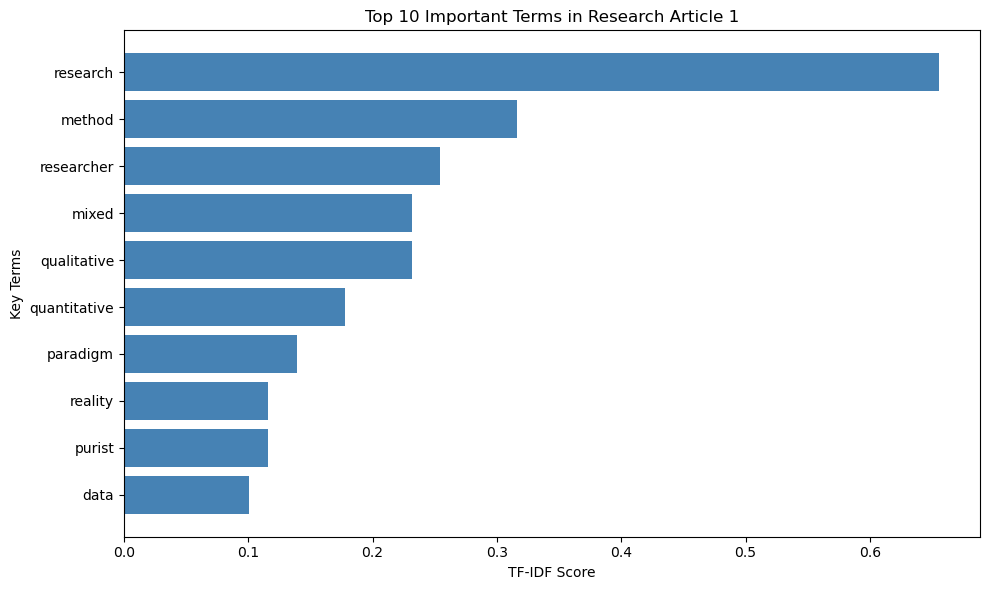

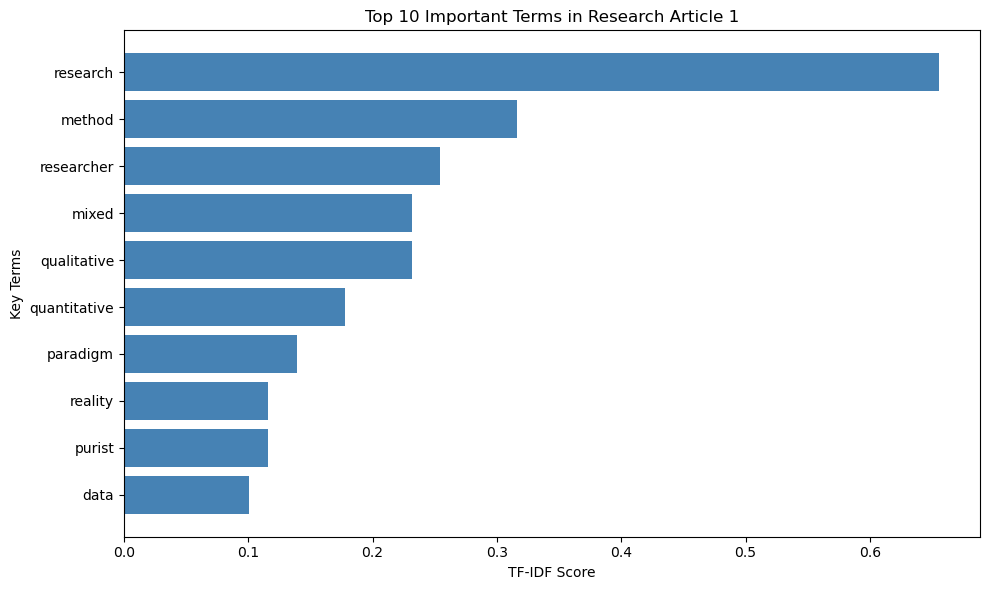

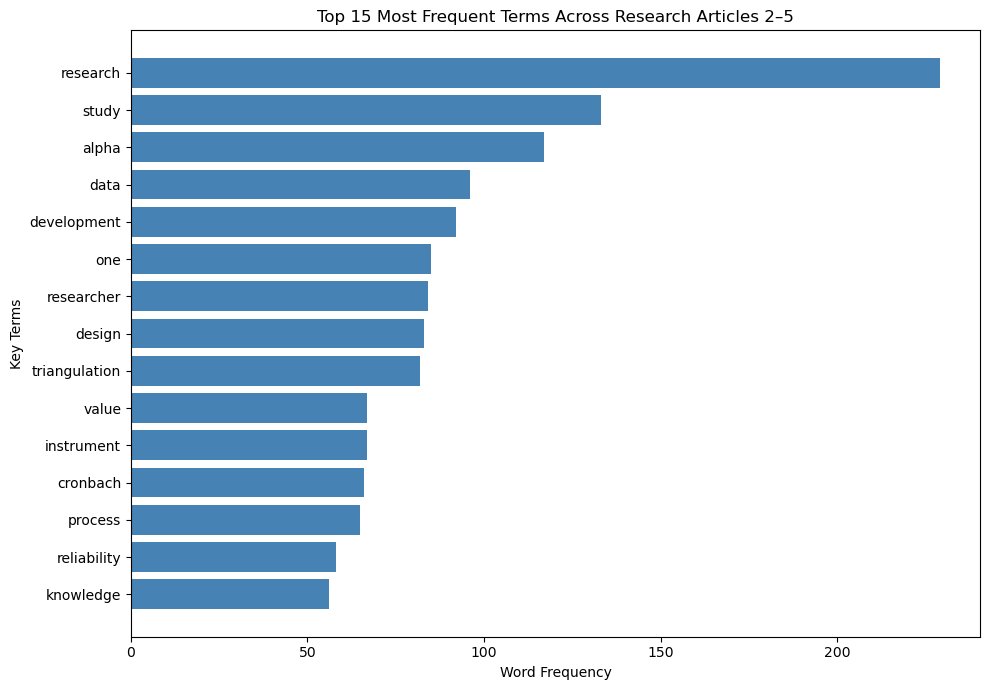

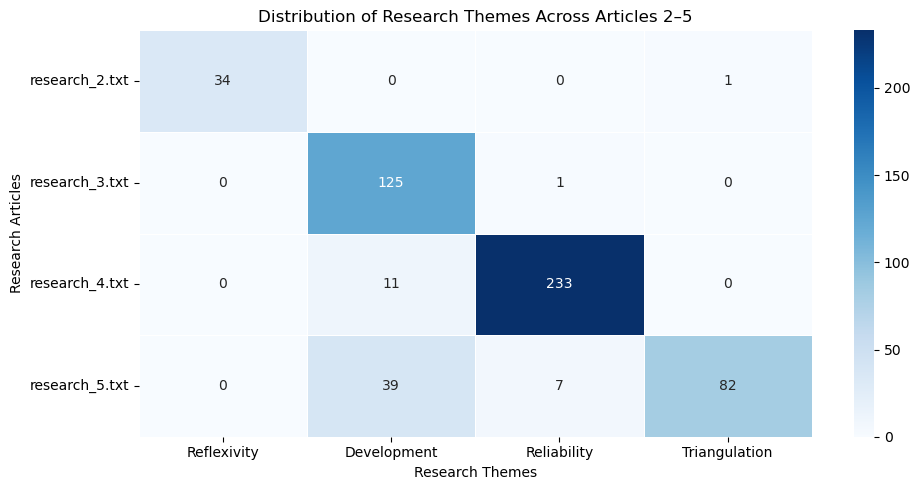

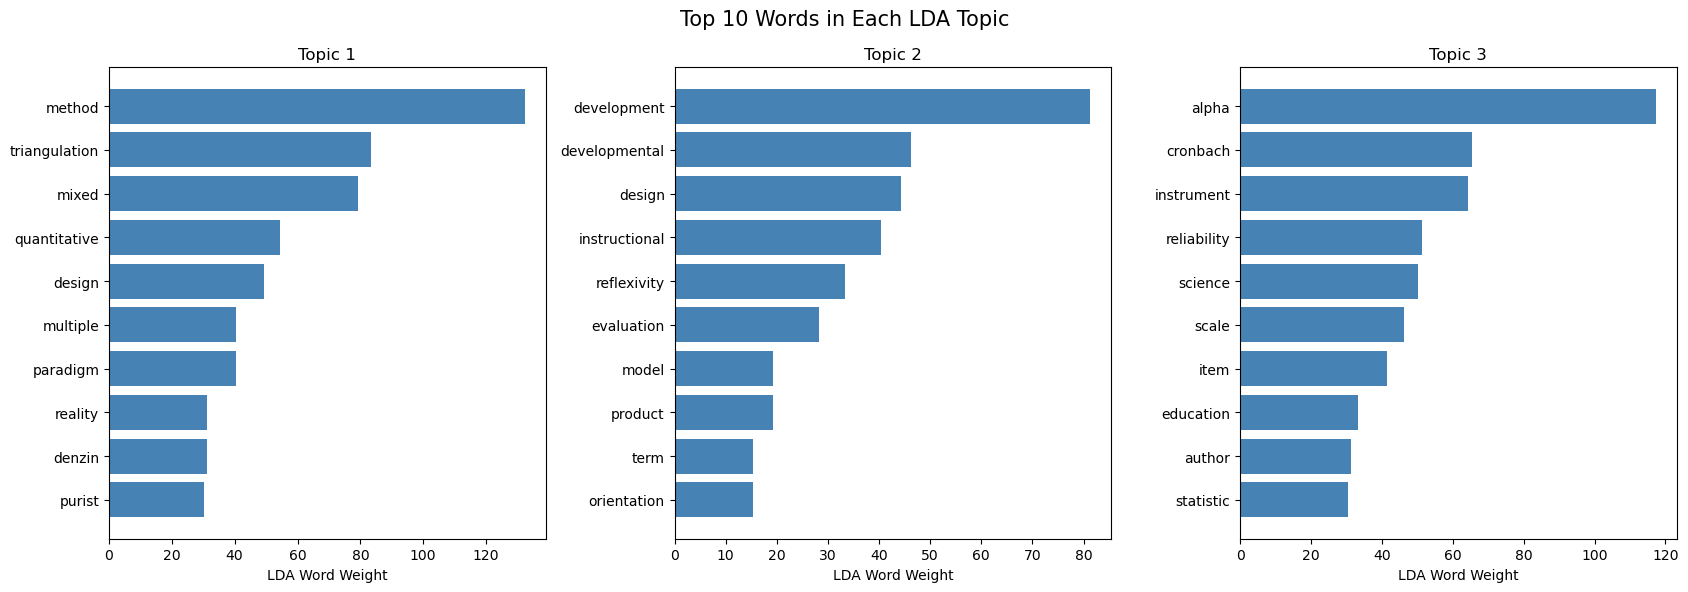

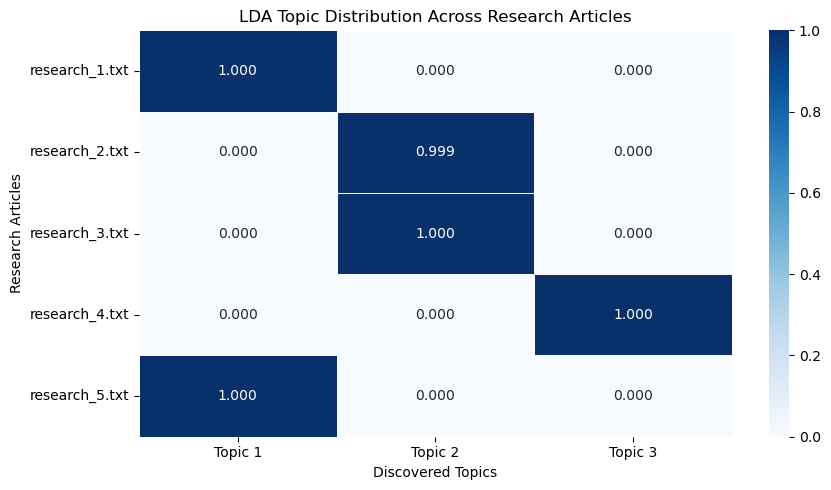

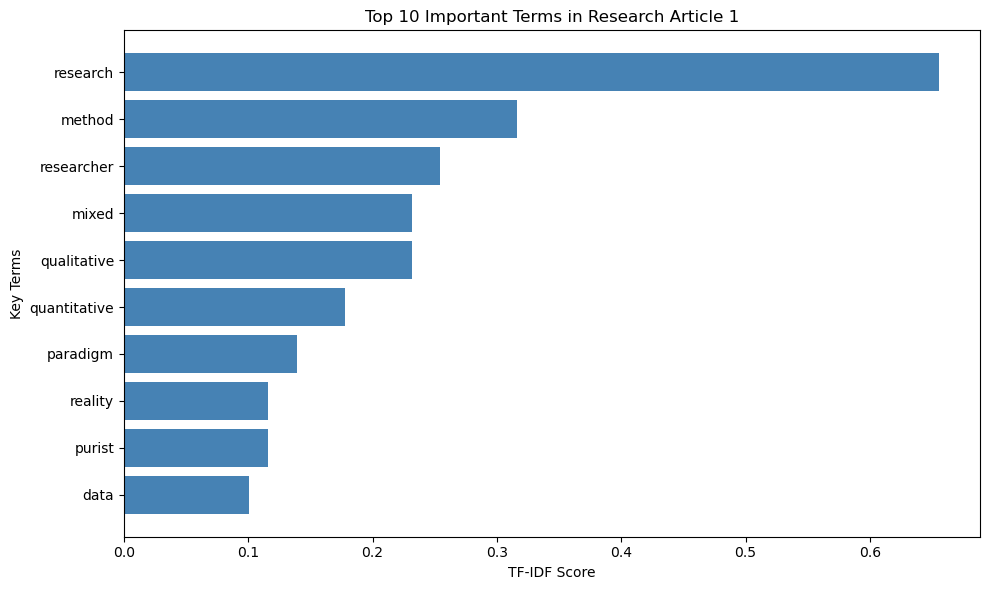

In [238]:
# Etract the cleaned content of the first article
cleaned_first_article = research_df.loc[0, "Cleaned_Content"]

# Calculate TF-IDF scores for terms in the article
word_vectorizer = TfidfVectorizer(max_features=1000)
word_matrix = word_vectorizer.fit_transform([cleaned_first_article])

# Get words and their TF-IDF scores
words = word_vectorizer.get_feature_names_out()
word_scores = word_matrix.toarray().flatten()

# Select the 10 highest-scoring words
top_word_indices = np.argsort(word_scores)[-10:]

# Create the visualisation
plt.figure(figsize=(10, 6))

plt.barh(
    words[top_word_indices],
    word_scores[top_word_indices],
    color="steelblue"
)

plt.xlabel("TF-IDF Score")
plt.ylabel("Key Terms")
plt.title("Top 10 Important Terms in Research Article 1")
plt.tight_layout()
plt.show()

Here, the first research article was summarised using TF-IDF and keyword scores to select five important sentences from the text. Duplicate sentences and sentences that were too long were removed to keep the summary clear and easy to read. The summary showed that the article mainly focused on mixed methods research, which combines qualitative and quantitative research approaches, with pragmatism as its philosophical foundation. A horizontal bar chart was also created to show the ten most common terms in the article. Words such as research, metod, researcher, mixed, qualitative and quantitative appeared prominently, which matched the main topic of the article. Since TF-IDF was applied to only one article for the chart, the scores mostly showed how often the words appeared rather than how unique they were compared to other articles.

#### Question 3.4

In [239]:
# Select articles 2 to 5
remaining_articles = research_df.iloc[1:].copy()

# Combine their original content one document
combined_text = "\n\n".join(remaining_articles["Content"])

# Explore
print("Number of articles:", len(remaining_articles))
print("Total words:", len(combined_text.split()))
print("Total characters:", len(combined_text))

Number of articles: 4
Total words: 16193
Total characters: 109020


In [240]:
# Split the combined articles into sentences
aggregate_sentences = sent_tokenize(combined_text)

# Remove duplicate and very short sentences
aggregate_sentences = list(dict.fromkeys(
    sentence.strip()
    for sentence in aggregate_sentences
    if len(sentence.split()) >= 8
))

print("Sentences available for TextRank:", len(aggregate_sentences))

Sentences available for TextRank: 542


In [241]:
from sklearn.metrics.pairwise import cosine_similarity

# Convert sentences into TF-IDF vectors
textrank_vectorizer = TfidfVectorizer(stop_words="english")

textrank_matrix = textrank_vectorizer.fit_transform(
    aggregate_sentences
)

# Calculate similarity between every pair of sentnces
similarity_matrix = cosine_similarity(textrank_matrix)

# Remove self-similarity
np.fill_diagonal(similarity_matrix, 0)

print("Similarity matrix shape:", similarity_matrix.shape)

Similarity matrix shape: (542, 542)


In [242]:
import networkx as nx

# Create a graph from the sentence similarity matrix
sentence_graph = nx.from_numpy_array(similarity_matrix)

# Apply PageRank to calculate sentence importance
textrank_scores = nx.pagerank(
    sentence_graph,
    weight="weight"
)

# Select the 8 highest-ranked sentences
top_sentence_indices = sorted(
    sorted(textrank_scores, key=textrank_scores.get, reverse=True)[:8]
)

print("Selected sentence indices:", top_sentence_indices)

Selected sentence indices: [61, 179, 246, 250, 393, 413, 434, 470]


In [243]:
# Final balanced TextRank summary of articles 2–5

import re

balanced_summary_sentences = []

for article_name, article_text in zip(
    remaining_articles["Article"],
    remaining_articles["Content"]
):
    candidates = []

    for sentence in sent_tokenize(article_text):
        sentence = sentence.strip()
        cleaned = " ".join(sentence.split())
        lower = cleaned.lower()

        # Keep reasonably sized sentences
        if not (12 <= len(cleaned.split()) <= 50):
            continue

        # Require a complete sentence
        if not cleaned.endswith((".", "!", "?")):
            continue

        # Remove headings, keywords and formatting artefacts
        if any(term in lower for term in [
            "keywords",
            "journal of social change",
            "denzin’s paradigm shift:",
            "the use of cronbach’s alpha in",
            "the frequency of use of cronbach’s alpha",
            "introduction researchers"
        ]):
            continue

        if any(symbol in cleaned for symbol in ["⇒", "\x01", "■", "●"]):
            continue

        # Exclude unbalanced brackets
        if cleaned.count("(") != cleaned.count(")"):
            continue

        # Use the existing TextRank score
        if sentence in aggregate_sentences:
            index = aggregate_sentences.index(sentence)
            candidates.append(
                (cleaned, textrank_scores[index])
            )

    # Choose the two highest-ranked sentences per article
    top_sentences = sorted(
        candidates,
        key=lambda item: item[1],
        reverse=True
    )[:2]

    balanced_summary_sentences.extend(
        sentence for sentence, score in top_sentences
    )

    print(f"{article_name}: {len(top_sentences)} sentences selected")

# Combine the eight selected sentences
balanced_summary = " ".join(balanced_summary_sentences)

# Remove the remaining section heading
balanced_summary = balanced_summary.replace(
    "Qualitative Research and Triangulation The application",
    "The application"
)

print("\nFINAL TEXTRANK AGGREGATE SUMMARY")
print("-" * 55)
print(balanced_summary)

research_2.txt: 2 sentences selected
research_3.txt: 2 sentences selected
research_4.txt: 2 sentences selected
research_5.txt: 2 sentences selected

FINAL TEXTRANK AGGREGATE SUMMARY
-------------------------------------------------------
Reflexivity is crucial throughout all phases of the research process, including the formulation of a research question, collection and analysis of data, and drawing conclusions (Bradbury-Jones, 2007; Guillemin and Gillam, 2004). Relative to the contribution of reflexivity to keeping the process of research ethical, Pillow (2003) stated that ‘reflexivity is situating the researcher as non-exploitative and compassionate toward the research subjects’, thus helping to address concerns regarding negative effects of power in researcher–researched relationships. While results from research in these areas impact the development process, the study of variables embedded in such topics does not constitute developmental research. While instructional development ty

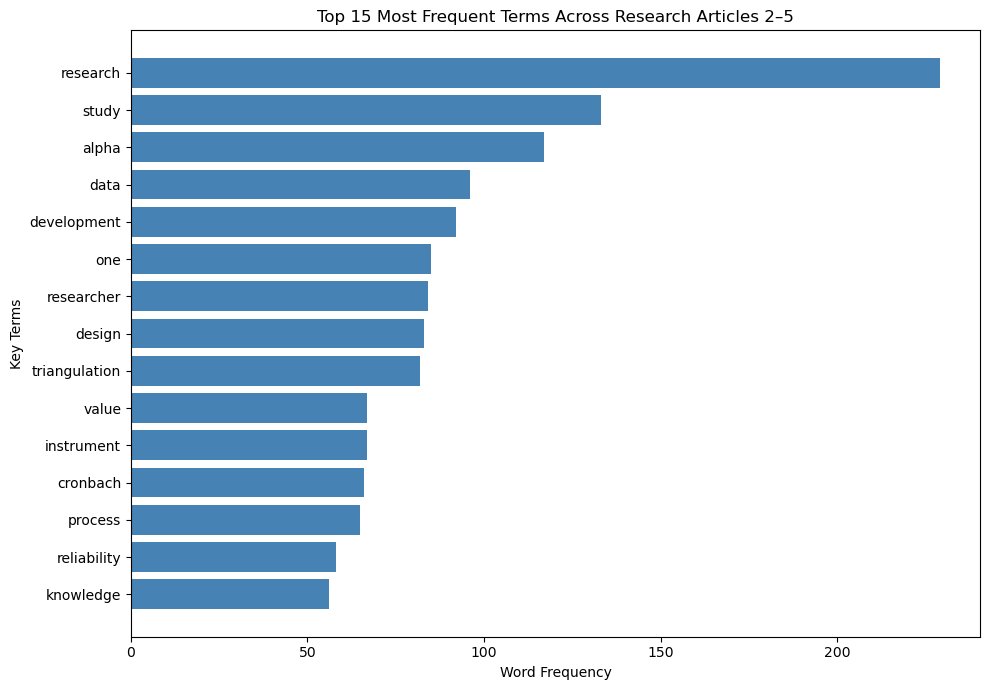

In [244]:
from collections import Counter

# Combine the cleaned content of articles 2–5
aggregate_cleaned_text = " ".join(
    remaining_articles["Cleaned_Content"]
)

# Count word frequencies
word_counts = Counter(aggregate_cleaned_text.split())

# Select the 15 most frequent words
top_words = word_counts.most_common(15)

words = [word for word, count in top_words]
frequencies = [count for word, count in top_words]

# Create a horizontal bar chart
plt.figure(figsize=(10, 7))

plt.barh(
    words[::-1],
    frequencies[::-1],
    color="steelblue"
)

plt.xlabel("Word Frequency")
plt.ylabel("Key Terms")
plt.title("Top 15 Most Frequent Terms Across Research Articles 2–5")

plt.tight_layout()
plt.show()

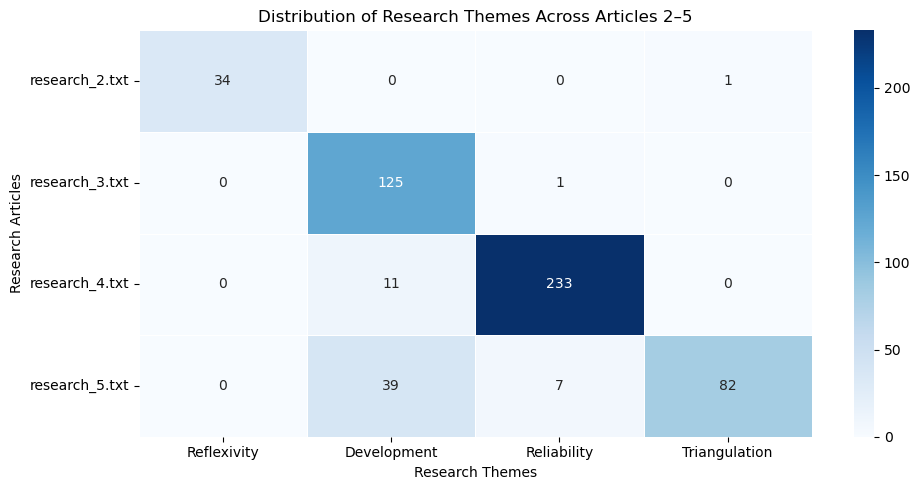

In [245]:
import seaborn as sns
import pandas as pd

# Define key research themes
theme_keywords = {
    "Reflexivity": ["reflexivity", "reflexive"],
    "Development": ["development", "design"],
    "Reliability": ["reliability", "alpha", "cronbach"],
    "Triangulation": ["triangulation", "triangulate"]
}

# Count theme related words 
theme_data = []

for _, row in remaining_articles.iterrows():
    words = row["Cleaned_Content"].split()

    counts = {
        theme: sum(words.count(keyword) for keyword in keywords)
        for theme, keywords in theme_keywords.items()
    }

    counts["Article"] = row["Article"]
    theme_data.append(counts)

# Create a DataFrame for the heatmap
theme_df = pd.DataFrame(theme_data).set_index("Article")

# Visualise theme frequencies
plt.figure(figsize=(10, 5))

sns.heatmap(
    theme_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Distribution of Research Themes Across Articles 2–5")
plt.xlabel("Research Themes")
plt.ylabel("Research Articles")

plt.tight_layout()
plt.show()

Here, the remaining four research articles were summarised together using TextRank. TF-IDF and cosine similarity were used to compare the sentences, while PageRank helped identify the most important ones. 

Two sentences were selected from each article to create a summary of eight sentences. The summary showed that the articles mainly focused on researcher reflexivity, developmental research, instrument reliablity and triangulation. 

Then a horizontal bar chart was then created to show the 15 most common words across the four articles, including research, study, alpha, development, triangulation and reliability. A heatmap was also created to compare the main research themes in each article.

The results show that Article 2 focused mostly on reflexivity with 34 occurrences, Article 3 on development with 125 occurrences, Article 4 on reliability with 233 occurrences and Article 5 on tringulation with 82 occurrences. 

Although the articles covered different topics, they all focused on improving research methods and the quality of research. Overall, the summary helped bring the main ideas from the four articles together, while the charts made it easier to see the common words and the main topic of each article.

## QUESTION 4

#### Question 4.1

In [246]:
#Prepare
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Convert cleaned articles into a document-term matrix
lda_vectorizer = CountVectorizer(
    max_df=0.95,
    min_df=1,
    max_features=2000
)

lda_matrix = lda_vectorizer.fit_transform(
    research_df["Cleaned_Content"]
)

print("Number of documents:", lda_matrix.shape[0])
print("Number of vocabulary terms:", lda_matrix.shape[1])
#CountVectorizer rather than TF-IDF because standard LDA models word-count frequencies.

Number of documents: 5
Number of vocabulary terms: 2000


In [247]:
# Set number of topics
n_topics = 4

# Create LDA model
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    max_iter=100,
    learning_method="batch"
)

# Train model and obtain topic distributions
document_topics = lda_model.fit_transform(lda_matrix)

print("LDA model trained successfully!")
print("Number of topics:", lda_model.n_components)
print("Document-topic matrix shape:", document_topics.shape)

LDA model trained successfully!
Number of topics: 4
Document-topic matrix shape: (5, 4)


In [248]:
#Display top 10 words for each LDA topic
# Get vocabulary words
feature_names = lda_vectorizer.get_feature_names_out()

# Choos number of words to display per topic
n_top_words = 10

# Display ttop words for each topic
for topic_idx, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-n_top_words:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"Topic {topic_idx + 1}:")
    print(", ".join(top_words))
    print("-" * 60)

Topic 1:
triangulation, method, design, denzin, fusch, multiple, source, mixed, bias, change
------------------------------------------------------------
Topic 2:
development, developmental, design, instructional, reflexivity, evaluation, model, product, term, orientation
------------------------------------------------------------
Topic 3:
cooperative, asked, abstract, idea, opportunity, argue, detailed, checking, employment, differentiate
------------------------------------------------------------
Topic 4:
alpha, method, instrument, cronbach, science, mixed, reliability, quantitative, scale, item
------------------------------------------------------------


In [249]:
# Create a DataFrame showing topic probabilities for each article
topic_columns = [f"Topic {i + 1}" for i in range(n_topics)]

topic_distribution_df = pd.DataFrame(
    document_topics,
    columns=topic_columns
)

# Add article names
topic_distribution_df.insert(
    0,
    "Article",
    research_df["Article"].values
)

# Display topic probabilities
display(topic_distribution_df.round(3))

# Check that each article's probabilities sum to 1
print(
    "Probability sums:",
    document_topics.sum(axis=1).round(3)
)

,Article,Topic 1,Topic 2,Topic 3,Topic 4
0,research_1.txt,0.0,0.000,0.0,1.0
1,research_2.txt,0.0,0.999,0.0,0.0
2,research_3.txt,0.0,1.000,0.0,0.0
3,research_4.txt,0.0,0.000,0.0,1.0
4,research_5.txt,1.0,0.000,0.0,0.0


Probability sums: [1. 1. 1. 1. 1.]


In [250]:
# Test an alternative LDA model with 3 topics
lda_model_3 = LatentDirichletAllocation(
    n_components=3,
    random_state=42,
    max_iter=100,
    learning_method="batch"
)

document_topics_3 = lda_model_3.fit_transform(lda_matrix)

# Display top 10 words for each topic
for topic_idx, topic in enumerate(lda_model_3.components_):
    top_indices = topic.argsort()[-10:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"Topic {topic_idx + 1}:")
    print(", ".join(top_words))
    print("-" * 50)

# Display document-topic probabilities
topic_df_3 = pd.DataFrame(
    document_topics_3,
    columns=["Topic 1", "Topic 2", "Topic 3"]
)

topic_df_3.insert(0, "Article", research_df["Article"].values)

display(topic_df_3.round(3))

Topic 1:
method, triangulation, mixed, quantitative, design, multiple, paradigm, reality, denzin, purist
--------------------------------------------------
Topic 2:
development, developmental, design, instructional, reflexivity, evaluation, model, product, term, orientation
--------------------------------------------------
Topic 3:
alpha, cronbach, instrument, reliability, science, scale, item, education, author, statistic
--------------------------------------------------


,Article,Topic 1,Topic 2,Topic 3
0,research_1.txt,1.0,0.000,0.0
1,research_2.txt,0.0,0.999,0.0
2,research_3.txt,0.0,1.000,0.0
3,research_4.txt,0.0,0.000,1.0
4,research_5.txt,1.0,0.000,0.0


Here, the number of topics was chosen by testing LDA with four topics and then three topics thereafter. The four-topic model produced one topic that was difficult to understand and barely appeared in any of the five research articles. This suggested that four topics were too many for the small dataset. The three-topic model gave clearer results. All three topics appeared in the articles, meaning that none of them were left unused. The three-topic model  gave a better overview of the articles. For this reason, three topics were selected because they were easier to understand and represented the main themes in the dataset more clearly.

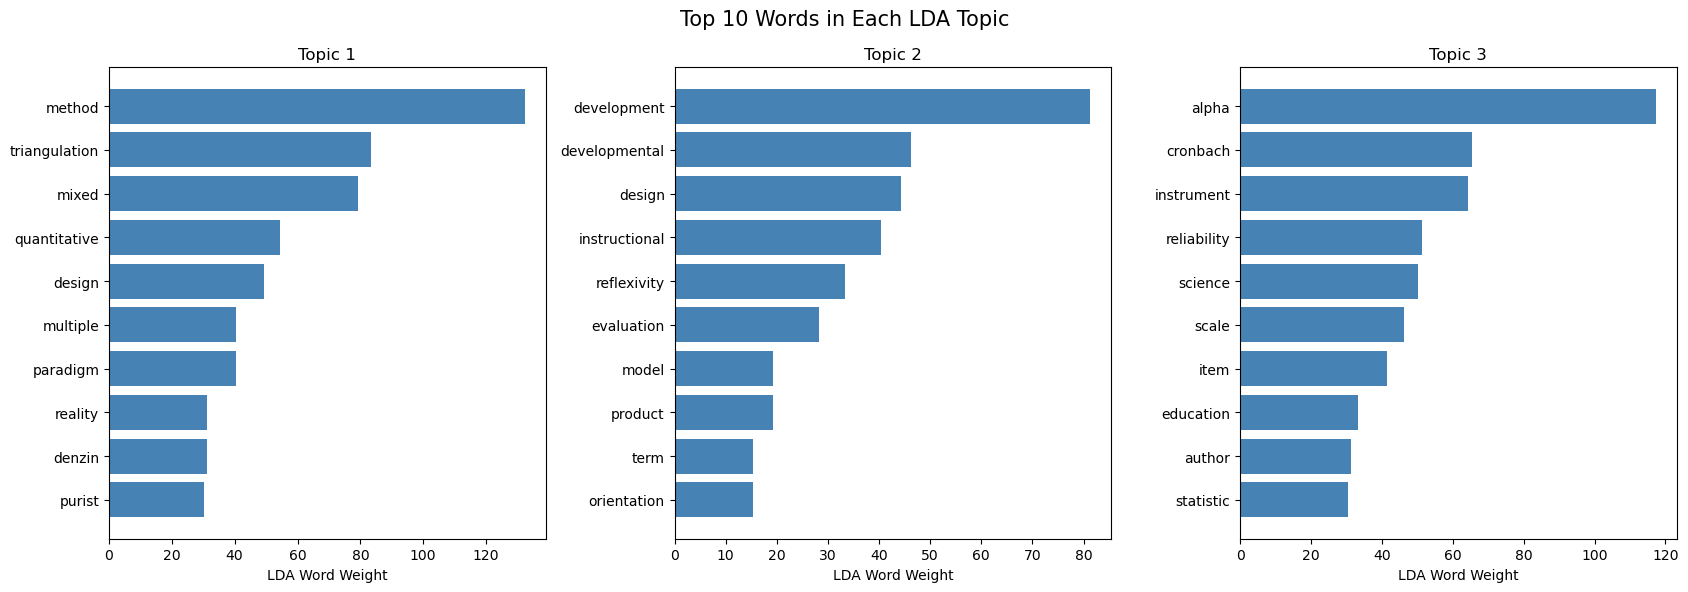

In [251]:
# Visualise top 10 words in each LDA topic
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(17, 6))

for topic_idx, topic in enumerate(lda_model_3.components_):
    top_indices = np.argsort(topic)[-10:]

    top_words = feature_names[top_indices]
    top_weights = topic[top_indices]

    axes[topic_idx].barh(
        top_words,
        top_weights,
        color="steelblue"
    )

    axes[topic_idx].set_title(f"Topic {topic_idx + 1}")
    axes[topic_idx].set_xlabel("LDA Word Weight")

plt.suptitle("Top 10 Words in Each LDA Topic", fontsize=15)
plt.tight_layout()
plt.show()

,Topic 1,Topic 2,Topic 3
Article,,,
research_1.txt,1.0,0.000,0.0
research_2.txt,0.0,0.999,0.0
research_3.txt,0.0,1.000,0.0
research_4.txt,0.0,0.000,1.0
research_5.txt,1.0,0.000,0.0


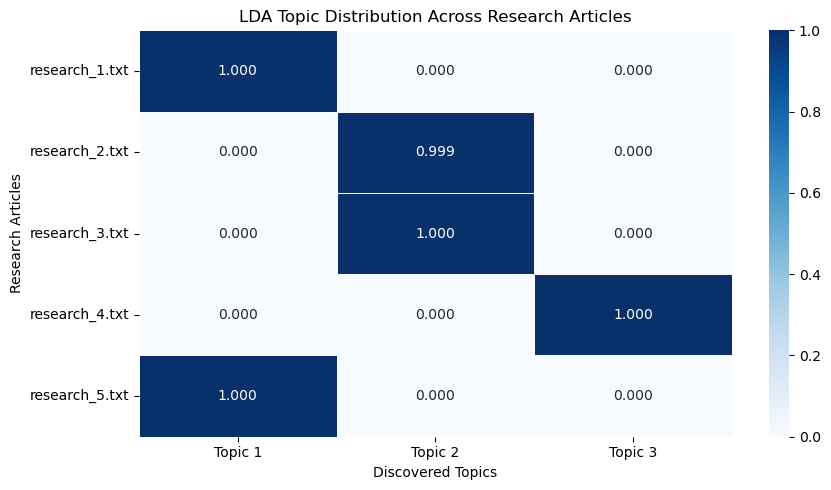

In [252]:
import seaborn as sns

# Create a DataFrame of topic probabilities
lda_topic_distribution = pd.DataFrame(
    document_topics_3,
    columns=["Topic 1", "Topic 2", "Topic 3"],
    index=research_df["Article"]
)

# Display topic distribution table
display(lda_topic_distribution.round(3))

# Visualise  using a heatmap
plt.figure(figsize=(9, 5))

sns.heatmap(
    lda_topic_distribution,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5
)

plt.title("LDA Topic Distribution Across Research Articles")
plt.xlabel("Discovered Topics")
plt.ylabel("Research Articles")

plt.tight_layout()
plt.show()

Here, LDA was used on the five clened research articles to identify the main topics discussed in the dataset. CountVectorizer was used to convert the text into numerical values. Models with four and three topics were tested, but three topics were selected because the results were easier to understand. 
- Topic 1 focused on mixed research methods and triangulation, with words such as method, triangulation, mixed and quantitative. 
- Topic 2 focused on developmental research and researcher reflexivity, with words such as development, design, instructional and reflexivity. 
- Topic 3 focused on instrument reliability and Cronbach's alpha, with words such as alpha, cronbach, instrument and reliability. 

A bar chart was then created to show the ten most important words in each topic, while a heatmap was used to show how the topics were distributed across the five articles. The heatmap showed that Articles 1 and 5 were mainly linked to Topic 1, Articles 2 and 3 to Topic 2, and Article 4 to Topic 3. Each article was strongly linked to one main topic, although the results should be considered carefully since only five articles were used. 
Overall, LDA helped identify the main themes in the articles and made it easier to see how the articles were grouped according to their topics.

#### Question 4.2

In [253]:
#%pip install pyLDAvis

In [254]:
import pyLDAvis
import pyLDAvis.lda_model

lda_vis = pyLDAvis.lda_model.prepare(
    lda_model_3,
    lda_matrix,
    lda_vectorizer,
    mds="pcoa",
    n_jobs=1
)

pyLDAvis.display(lda_vis)

In [255]:
# Save interactive Intertopic Distance Map as an HTML file
pyLDAvis.save_html(lda_vis, "intertopic_distance_map.html")

print("Interactive Intertopic Distance Map saved successfully!")

Interactive Intertopic Distance Map saved successfully!


The interactive Intertopic Distance Map was generated using pyLDAvis to visualise the three topics identified by the LDA

The circles represent the topics, with their sizes indicating their relative prevalence in the corpus. The distances between circles provide an approximate indication of how differemt the topics are based on their word distributions.

The panel on the right displays the most notable terms across the model. Selecting an individual topic displays its most relevant words, allowing the themes  to be explored interactively.

The three topics broadly represent mixed-methods research and triangulation, developmental research and reflexivity and research instrument reliability. The visualisation supports interpretation of the LDA result

#### Question 4.3

In [260]:
from pathlib import Path
import shutil

# It is commented out because the folders have already been created.

# project_dir = Path("itnpa-research-project")

# for folder in ["datasets", "notebooks", "deployment", "visualizations"]:
#     (project_dir / folder).mkdir(parents=True, exist_ok=True)

# print("GitHub folders created successfully")

# The notebook is now stored inside the notebooks folder.
# Go up one level to access the repository.

project_dir = Path("..").resolve()

print("Repository location:", project_dir)

Repository location: /Users/tashmikamaharaj/Desktop/Honours /Honours 2026/ITNPA4-34/Project 1/itnpa-research-project


In [261]:
# The original datasets were copied into the datasets folder.
# This was completed during the initial repository setup.

# for filename in ["research_abstracts.json", "research_corpus.zip"]:
#     shutil.copy2(filename, project_dir / "datasets" / filename)

# print("Datasets copied successfully")

# Check that both datasets are available.

for filename in ["research_abstracts.json", "research_corpus.zip"]:
    file_path = project_dir / "datasets" / filename

    if file_path.exists():
        print(f"Found: {filename}")
    else:
        print(f"Missing: {filename}")

Found: research_abstracts.json
Found: research_corpus.zip


In [262]:
# The Streamlit application and saved model files were copied
# into the deployment folder during the repository setup.

# shutil.copytree(
#     "deployment",
#     project_dir / "deployment",
#     dirs_exist_ok=True
# )

# print("Deployment files copied successfully")

# Check the deployment files.

deployment_files = [
    "app.py",
    "requirements.txt",
    "README.md",
    "tfidf_vectorizer.pkl",
    "feature_selector.pkl",
    "random_forest_model.pkl"
]

for filename in deployment_files:
    file_path = project_dir / "deployment" / filename

    if file_path.exists():
        print(f"Found: {filename}")
    else:
        print(f"Missing: {filename}")

Found: app.py
Found: requirements.txt
Found: README.md
Found: tfidf_vectorizer.pkl
Found: feature_selector.pkl
Found: random_forest_model.pkl


In [263]:
# The interactive LDA visualisation was copied into visualizations folder during the repository setup.

# shutil.copy2(
#     "intertopic_distance_map.html",
#     project_dir / "visualizations" / "intertopic_distance_map.html"
# )

# print("Interactive LDA map copied successfully")

# Check that the visualisation is available.

visualization_file = (
    project_dir / "visualizations" / "intertopic_distance_map.html"
)

if visualization_file.exists():
    print("Interactive LDA map found successfully")
else:
    print("Interactive LDA map is missing")

Interactive LDA map found successfully


In [264]:

# README documentation for the GitHub repository

readme = """# ITNPA Research Project

## Project Overview

This project focuses on using Natural Language Processing (NLP) and Machine Learning to classify, summarise and analyse research papers.

The project covers Questions 1 to 4, where I worked with research abstracts and articles using different machine learning and text analysis techniques. The repository contains the datasets, Jupyter Notebook, visualisations and Streamlit application used in the project.

## Question 1: Research Abstract Classification

For Question 1, I cleaned the research abstracts and used TF-IDF to convert the text into numerical features that a machine learning model could understand.

I then trained a Logistic Regression model to classify the abstracts as either AI Research or Classical Research.

The model achieved:
- Training accuracy: 90.86%
- Testing accuracy: 88.16%

## Question 2: Model Comparison, Improvement and Deployment

For Question 2, I tested four more machine learning models to see whether they could perform better than Logistic Regression.

The models were:
- Multinomial Naive Bayes
- Linear Support Vector Machine (SVM)
- Random Forest
- Decision Tree

Random Forest achieved the highest testing accuracy out of these four models.

I then tried different ways to improve its performance, including hyperparameter tuning, class weighting and feature engineering. The best results came from improving the TF-IDF features by including single words and two-word phrases, followed by chi-squared feature selection.

The improved Random Forest achieved a testing accuracy of 93.42%.

I also created a Streamlit web application where users can enter a research abstract and get a prediction of whether it belongs to AI Research or Classical Research.

## Question 3: Research Document Analysis

For Question 3, I worked with five research articles that were provided in a ZIP file.

The articles were cleaned by removing unnecessary characters and stopwords, followed by text preprocessing.

I used TF-IDF to summarise the first article by selecting important sentences. For the remaining four articles, I used TextRank to create a combined summary.

I also created bar charts to show the most common words and a heatmap to compare the main research themes across the articles.

## Question 4: Topic Modelling and Visualisation

For Question 4, I used Latent Dirichlet Allocation (LDA) to identify the main topics discussed in the five research articles.

I tested models with four and three topics and selected three because the results were easier to understand and represented the articles better.

The three topics focused on:
- Mixed research methods and triangulation
- Developmental research and researcher reflexivity
- Instrument reliability and Cronbach's alpha

I created charts to show the most important words in each topic and a heatmap to show how the topics were distributed across the articles.

I also used pyLDAvis to create an interactive Intertopic Distance Map to explore the topics and their most relevant words.

## Repository Structure

The project files are organised into the following folders:

- `datasets/` - Contains the original datasets used in the project.
- `notebooks/` - Contains the Jupyter Notebook with the code, explanations and results for Questions 1 to 4.
- `deployment/` - Contains the Streamlit application, saved model files and instructions for running the application.
- `visualizations/` - Contains the interactive LDA visualisation.

## Running the Notebook

1. Download or clone the repository.
2. Open the Jupyter Notebook inside the `notebooks` folder.
3. Install the Python libraries used in the notebook.
4. Run the cells in order to view the analysis and results.

## Running the Streamlit Application

Instructions for running the web application can be found in `deployment/README.md`.

## Notes

This project was completed as part of my academic assessment. The models were trained and tested using the provided datasets, so the results may be different when working with other research papers.
"""

# The README has already been created and updated on GitHub.
# This line is kept commented out to avoid overwriting it.

# (project_dir / "README.md").write_text(readme, encoding="utf-8")

print("README documentation prepared successfully")


README documentation prepared successfully


In [265]:
# Create  .gitignore file to exclude unnecessary files.

gitignore = """# Jupyter temporary files
.ipynb_checkpoints/

# Python temporary files
__pycache__/
*.pyc

# macOS system files
.DS_Store

# Virtual environments
.venv/
venv/

# Streamlit local settings
.streamlit/secrets.toml
"""

# Save the .gitignore file in the repository.
(project_dir / ".gitignore").write_text(
    gitignore,
    encoding="utf-8"
)

print(".gitignore created successfully")

.gitignore created successfully


In [266]:
# Check files

files_to_check = [
    "README.md",
    ".gitignore",
    "datasets/research_abstracts.json",
    "datasets/research_corpus.zip",
    "notebooks/ITNPA_Research_Project.ipynb",
    "deployment/app.py",
    "deployment/requirements.txt",
    "deployment/README.md",
    "deployment/tfidf_vectorizer.pkl",
    "deployment/feature_selector.pkl",
    "deployment/random_forest_model.pkl",
    "visualizations/intertopic_distance_map.html"
]

print("GitHub Repository File Check\n")

for filename in files_to_check:
    file_path = project_dir / filename

    if file_path.exists():
        print(f"Found: {filename}")
    else:
        print(f"Missing: {filename}")

GitHub Repository File Check

Found: README.md
Found: .gitignore
Found: datasets/research_abstracts.json
Found: datasets/research_corpus.zip
Found: notebooks/ITNPA_Research_Project.ipynb
Found: deployment/app.py
Found: deployment/requirements.txt
Found: deployment/README.md
Found: deployment/tfidf_vectorizer.pkl
Found: deployment/feature_selector.pkl
Found: deployment/random_forest_model.pkl
Found: visualizations/intertopic_distance_map.html


Here,  project files were organsed into separate folders before uploading them to GitHub. The datasets folder contains the research abstracts and research articles, while the notebooks folder contains the Jupyter Notebook with the code and results for Questions 1 - 4. The deployment folder contains the Streamlit application and saved model files. the visualizations folder contains the interactive LDA map. A README file to explain the project was created and how to run it, as well as a .gitignore file to exclude unnecessary files. Lastly, it was checked that the required files were saved in the correct folders. The repository was then prepared for uploading to GitHub so that the project files and analysis could be accessed in one place.